# Vanhamäki (2020) SECS Example using secsy

This notebook reproduces a compact spherical elementary current system (SECS) workflow using the Vanhamäki-style example grid and magnetometer perturbations, but with `secsy` for the SECS matrices. The goal is to infer a divergence-free equivalent ionospheric current sheet from ground magnetometer data, then visualise the measured perturbations, reconstructed magnetic field, fitted SECS amplitudes, and derived equivalent currents.

The steps follow the structure of the `SECSpy.SECS` example: define pole and evaluation grids, load magnetometer vectors, build the fitting matrix, solve for SECS amplitudes, evaluate magnetic fields and currents, and finally plot the results in a cubed-sphere projection.

## Imports and Load Data

The notebook uses the accompanying `Vanhamäki_2020_example_data.npz` file for the Vanhamäki-style grid and magnetometer data, `secsy` for the SECS response matrices, and Matplotlib plus `secsy.cubedsphere` for plotting. Magnetic data are handled in SI units inside the model and converted to nT or A km$^{-1}$ only when visualised.

The data file contains two longitude/latitude grids: SECS pole nodes and evaluation points. The pole nodes are where the elementary current systems are placed, while the evaluation grid is where we later reconstruct magnetic-field perturbations and horizontal currents.

The field components are in Tesla: `North` is the northward horizontal component, `East` is the eastward component, and `Up` is the radial component. `MagLon` and `MagLat` give the station coordinates in degrees. SECSpy uses the theta/southward component internally, so this notebook defines `South = -North` before assembling the inversion vector.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import inv, svd

from secsy.cubedsphere import CSgrid, CSprojection
from secsy import get_SECS_B_G_matrices, get_SECS_J_G_matrices

data_file = Path('Vanhamäki_2020_example_data.npz')
if not data_file.exists():
    data_file = Path('notebooks') / data_file

data = np.load(data_file)
node_lon = data['node_lon']
node_lat = data['node_lat']
eval_lon = data['eval_lon']
eval_lat = data['eval_lat']
North = data['North']
East = data['East']
Up = data['Up']
MagLon = data['MagLon']
MagLat = data['MagLat']

RE = 6371.2e3  # Earth radius in meters

## Construct the Inversion Matrix

`get_SECS_B_G_matrices(...)` builds the magnetic-field response matrices for unit-amplitude SECS poles at the magnetometer locations. For the default divergence-free system, each column describes the south, east, and radial magnetic perturbation produced by one SECS pole.

SECSpy stacks the rows as south, east, and up, so this notebook uses the same convention for the inversion even though the stored data component is northward.

In [ ]:
GeB_mag, GnB_mag, GuB_mag = get_SECS_B_G_matrices(MagLat, MagLon, RE, node_lat, node_lon)

G = np.vstack((GnB_mag, GeB_mag, GuB_mag)) 
d = np.hstack((North, East, Up))

## Solve for SECS Amplitudes

The fitting matrix maps the measured magnetometer vector to the best-fitting SECS amplitudes. As in SECSpy, it is formed as a Moore-Penrose pseudoinverse using singular value decomposition.

SECSpy decomposes `G.T @ G`, discards singular values smaller than `cond * max(singular values)`, forms `(G.T @ G)^+`, and then multiplies by `G.T` to obtain the matrix that is applied to the measured magnetometer vector.

In [3]:
def secspy_truncated_svd_fitting_matrix(G, cond=0.05**2):
    """Return the SECSpy-style fitting matrix for SECS amplitudes."""
    U, s, Vh = svd(G.T @ G)
    r = len(s)

    below_threshold = np.where(s < cond * np.max(s))[0]
    n_keep = below_threshold[0] if below_threshold.size else r

    invD = np.zeros((r, r))
    if n_keep > 0:
        invD[:n_keep, :n_keep] = inv(np.diag(s[:n_keep]))

    return Vh.T @ invD @ U.T @ G.T, s, n_keep


cond = 0.05**2
fitting_matrix, singular_values, n_singular_values_retained = secspy_truncated_svd_fitting_matrix(G, cond=cond)
amps = fitting_matrix @ d

## Reconstruct the Magnetic Field on the Evaluation Grid

The fitted SECS amplitudes are used to evaluate the magnetic perturbation at every evaluation-grid point. The returned tuple is arranged as radial, eastward, and northward components in Tesla.

The multiplication by `1e9` converts the modelled perturbations to nanotesla for plotting beside the measured magnetometer vectors.

In [ ]:
GeB, GnB, GuB = get_SECS_B_G_matrices(eval_lat, eval_lon, RE, node_lat, node_lon)

Mag = [ GuB.dot(amps) * 1e9, GeB.dot(amps) * 1e9, GnB.dot(amps) * 1e9]  # Convert to nanoTesla

## Evaluate the Equivalent Currents

The same fitted SECS amplitudes are used to evaluate the horizontal divergence-free current field rather than the magnetic field. The result represents the equivalent ionospheric current sheet implied by the fitted SECS system.

The returned arrays are eastward and northward current components in amps.

In [ ]:
Gej, Gnj = get_SECS_J_G_matrices(eval_lat, eval_lon, node_lat, node_lon)

Cur = [Gej.dot(amps), Gnj.dot(amps)]

## Prepare the Map Projection

The model geometry is geographic, but the figure is drawn in a cubed-sphere projection centred near northern Fennoscandia. `CSgrid` defines the plotting plane and `geo2cube` converts both SECS pole locations and evaluation points into projected `xi`/`eta` coordinates.

In [6]:
lon_centre= 20
lat_centre= 68.1
Gridproj= CSprojection((lon_centre, lat_centre), 0)
plot_grid=CSgrid(Gridproj, 2500, 3000, 50., 50.)
node_xi, node_eta= plot_grid.projection.geo2cube(node_lon, node_lat)
eval_xi, eval_eta= plot_grid.projection.geo2cube(eval_lon, eval_lat)

## Set Up the Three-Panel Figure

The figure is arranged as three map panels with matching horizontal colour bars: measured and modelled magnetic perturbations, SECS amplitudes, and divergence-free currents. Bundled Natural Earth ocean, land, lake, and coastline features are projected through the cubed-sphere grid so the geographic context matches the plotted vectors and grid points.

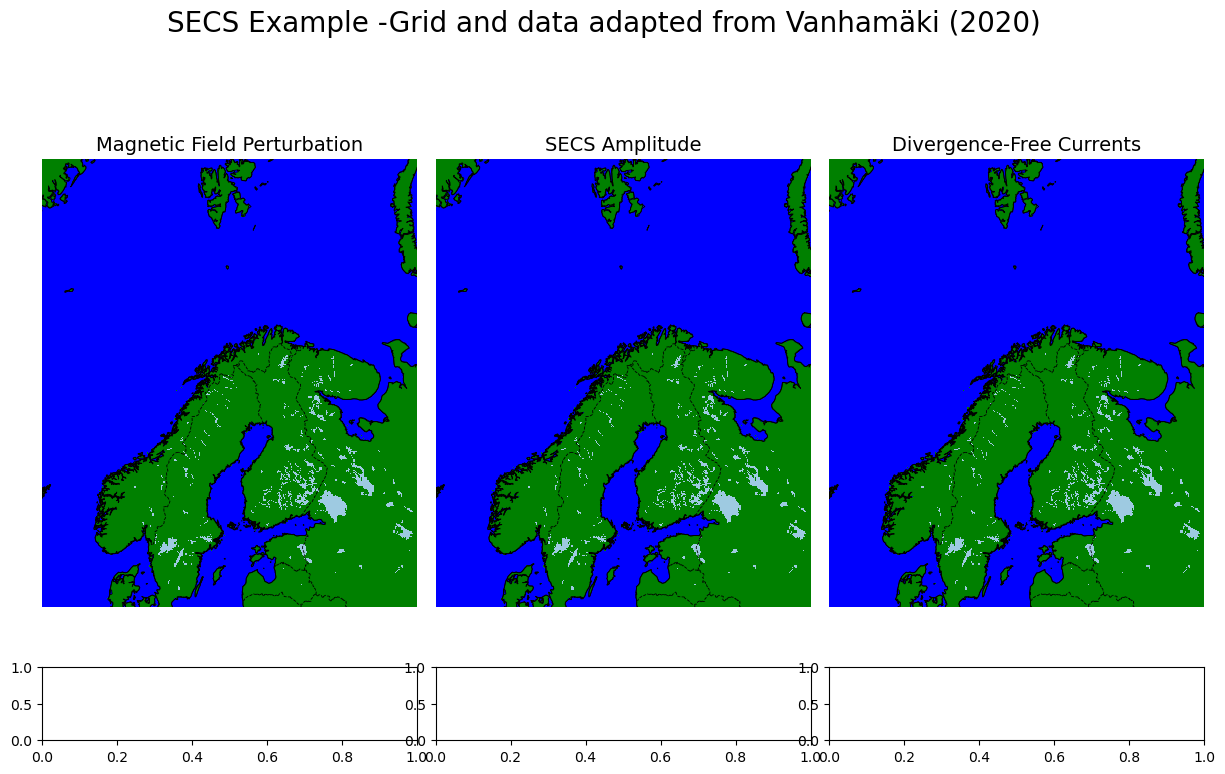

In [7]:

def align_axis_below(reference_axis, lower_axis, pad=0.1):
    """
    Place one Matplotlib axis directly below another and keep their widths aligned.

    The alignment is applied immediately and is also reapplied whenever the
    parent figure is resized.

    Parameters
    ----------
    reference_axis : matplotlib.axes.Axes
        Axis that defines the horizontal position, width, and upper anchor.
    lower_axis : matplotlib.axes.Axes
        Axis to move below ``reference_axis``. This is typically a colour-bar
        axis.
    pad : float, optional
        Vertical separation between the two axes in figure-coordinate units.
        The default is 0.1.

    Returns
    -------
    None
        Matplotlib ``set_position`` result from the initial alignment.
    """
    import functools

    def onresize(reference_axis, lower_axis, event):
        reference_position = reference_axis.get_position()
        lower_position = lower_axis.get_position()
        return lower_axis.set_position([
            lower_position.x0,
            reference_position.y0 - pad - lower_position.height,
            reference_position.width,
            lower_position.height,
        ])

    onresize_wrapper = functools.partial(onresize, reference_axis, lower_axis)
    callback_id = reference_axis.figure.canvas.mpl_connect(
        'resize_event',
        onresize_wrapper,
    )
    lower_axis._secspy_align_axis_below_callback_id = callback_id
    return onresize(reference_axis, lower_axis, None)

fig=plt.figure(figsize=(15, 20))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1], height_ratios=[1, .05], hspace=0, wspace=0.05)
mag_ax = fig.add_subplot(gs[0, 0])
mag_ax.set_title('Magnetic Field Perturbation', fontsize=14)
mag_cax = fig.add_subplot(gs[1, 0])
amps_ax = fig.add_subplot(gs[0, 1])
amps_ax.set_title('SECS Amplitude', fontsize=14)
amps_cax = fig.add_subplot(gs[1, 1])
cur_ax = fig.add_subplot(gs[0, 2])
cur_ax.set_title('Divergence-Free Currents', fontsize=14)
cur_cax = fig.add_subplot(gs[1, 2])
fig.suptitle('SECS Example -Grid and data adapted from Vanhamäki (2020)', y=.7, size=20)

for ax, cax in zip([mag_ax, amps_ax, cur_ax], [mag_cax, amps_cax, cur_cax]):
    plot_grid.add_natural_earth_feature(ax, 'ocean', resolution='10m', facecolor='blue', zorder=-4)
    plot_grid.add_natural_earth_feature(ax, 'land', resolution='10m', facecolor='green', zorder=-3)
    plot_grid.add_natural_earth_feature(
        ax, 'lakes', resolution='10m',
        facecolor='#9ecae1', edgecolor='none', linewidth=0, zorder=-2,
    )
    plot_grid.add_natural_earth_feature(
        ax, 'coastline', resolution='10m',
        edgecolor='black', linewidth=0.6, zorder=-1,
    )
    plot_grid.add_natural_earth_feature(
        ax, 'borders', resolution='10m',
        edgecolor='black', linewidth=0.6, zorder=-1, linestyle='--'
    )
    for cl in plot_grid.projection.get_projected_coastlines():
        ax.plot(cl[0], cl[1], color='black', linewidth=0.6, zorder=1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(plot_grid.xi.min(), plot_grid.xi.max())
    ax.set_ylim(plot_grid.eta.min(), plot_grid.eta.max())
    align_axis_below(ax, cax, pad=0.03)

## Overlay the Measured Magnetic Field

The station measurements are projected into the cubed-sphere plotting coordinates. The horizontal arrows use eastward and northward components from the data file. The station markers are coloured by the radial perturbation `Up`, all converted from Tesla to nanotesla.

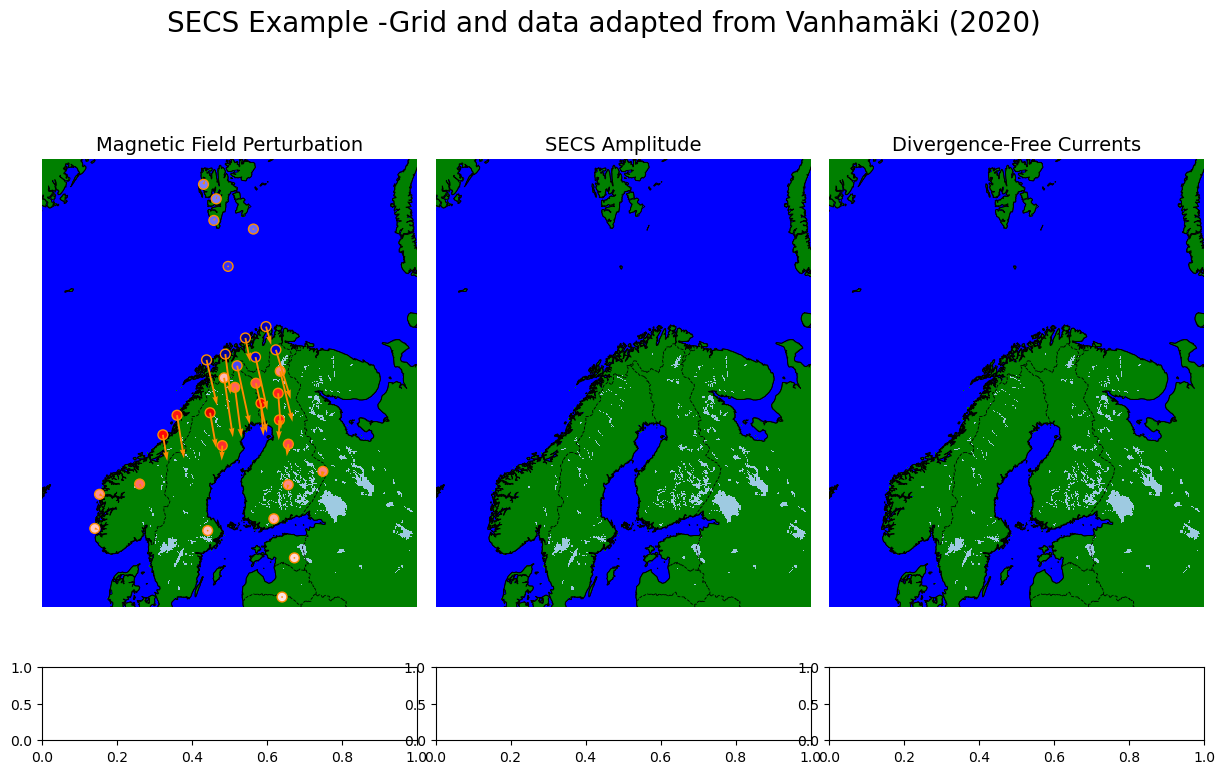

In [8]:
xi, eta, Axi, Aeta = plot_grid.projection.vector_cube_projection(East*1e9, North*1e9, MagLon, MagLat)
mag_ax.quiver(xi, eta, Axi, Aeta, zorder=120, color='darkorange', scale=(5e3), width=0.005)
mag_ax.scatter(xi, eta, marker= 'o', c= Up*1e9, label= 'Magnetometer \n Station',
                    cmap= 'seismic', vmin= -np.max(np.abs(Mag[0])), vmax= np.max(np.abs(Mag[0])), zorder=110, s=50,
                    edgecolor='darkorange')
fig

## Plot the Modelled Magnetic Field

The reconstructed field is evaluated on the regular evaluation grid. The scatter plot shows radial perturbation and the arrows show the modelled horizontal perturbation. Using the same colour limits as the measured stations makes the observed and reconstructed radial fields directly comparable.

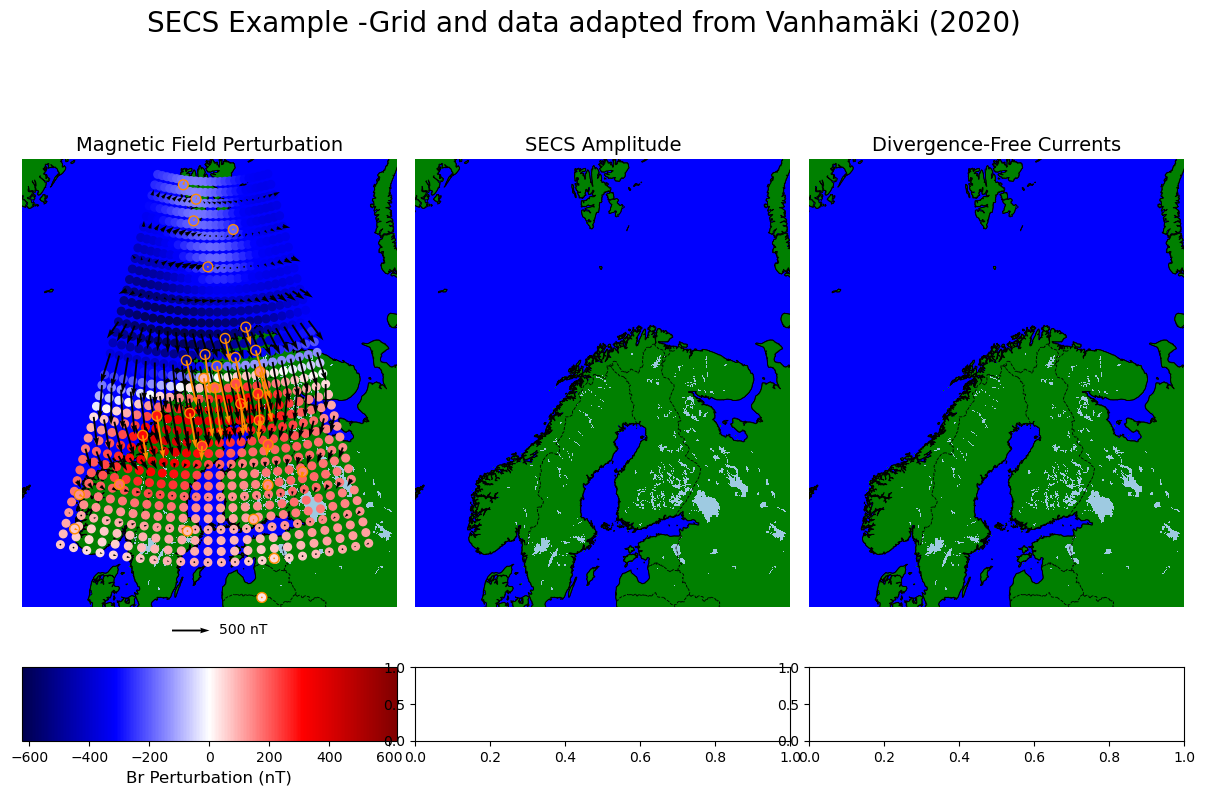

In [9]:
Axi, Aeta = plot_grid.projection.vector_cube_projection(*Mag[1:], eval_lon, eval_lat, return_xi_eta=False)

mags_s= mag_ax.scatter(eval_xi, eval_eta, marker= 'o', c= Mag[0], label= 'Magnetometer \n Station',
                    cmap= 'seismic', vmin= -np.max(np.abs(Mag[0])), vmax= np.max(np.abs(Mag[0])), zorder=1, s=30)
mag_cbar= fig.colorbar(mags_s, cax=mag_cax, orientation='horizontal')
mag_cbar.set_label('Br Perturbation (nT)', fontsize=12)
mag_quiver= mag_ax.quiver(eval_xi[::3], eval_eta[::3], Axi[::3], Aeta[::3], zorder=100, color='k', scale=(5e3), width=0.005)
mag_ax.quiverkey(mag_quiver, 0.5, -0.05, 500, '500 nT', labelpos='E', coordinates='axes', color='k')
fig

## Plot the SECS Pole Amplitudes

The fitted amplitude of each elementary current pole is plotted at the SECS pole-node coordinates. Values are multiplied by `1e-3` so the colour bar is labelled in kA.

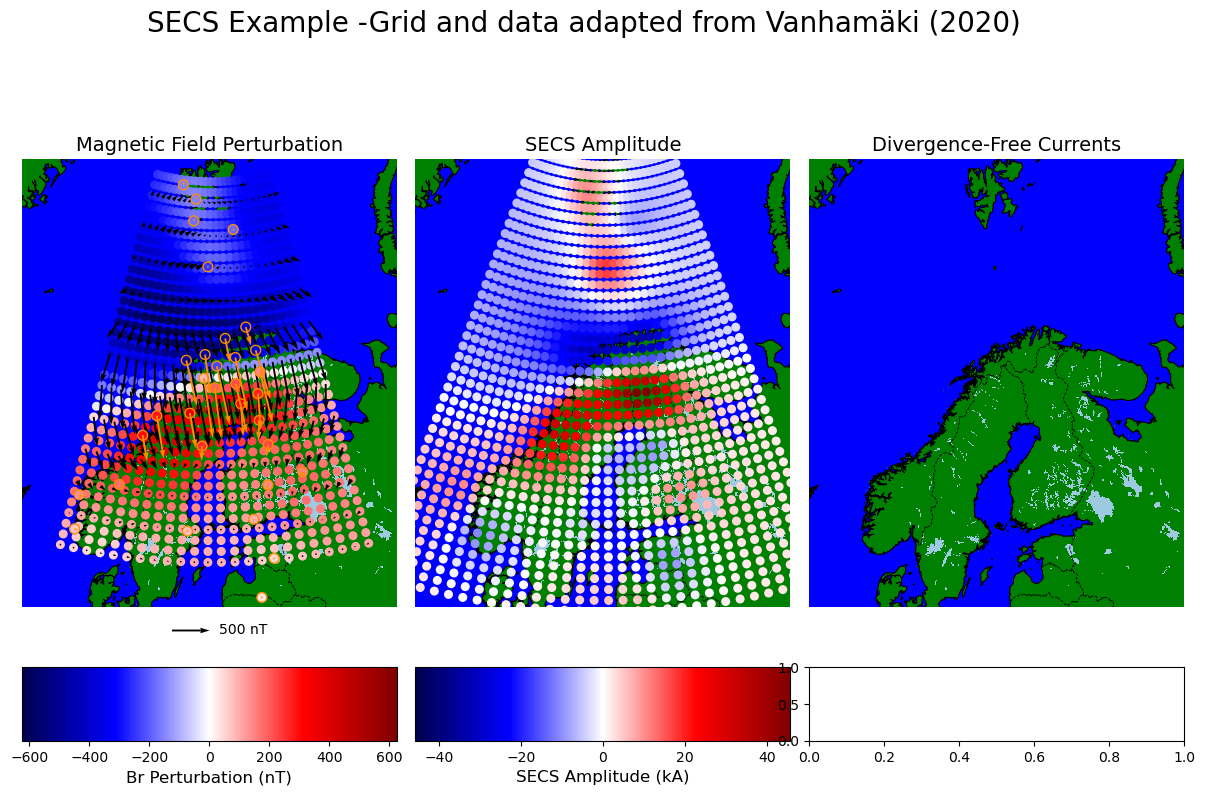

In [10]:
amps_kA = amps * 1e-3
amps_s = amps_ax.scatter(node_xi, node_eta, marker='o', c=amps_kA, 
                          cmap='seismic', zorder=1, s=30,
                          vmin=-np.max(np.abs(amps_kA)), vmax=np.max(np.abs(amps_kA)))
amps_cbar = fig.colorbar(amps_s, cax=amps_cax, orientation='horizontal')
amps_cbar.set_label('SECS Amplitude (kA)', fontsize=12)
fig

## Plot the Divergence-Free Current Field

The current vectors are converted to mA m$^{-1}$, equivalently A km$^{-1}$, for display. Arrows show direction and the background colour shows horizontal current magnitude. This final panel is the equivalent current pattern implied by the fitted divergence-free SECS system.

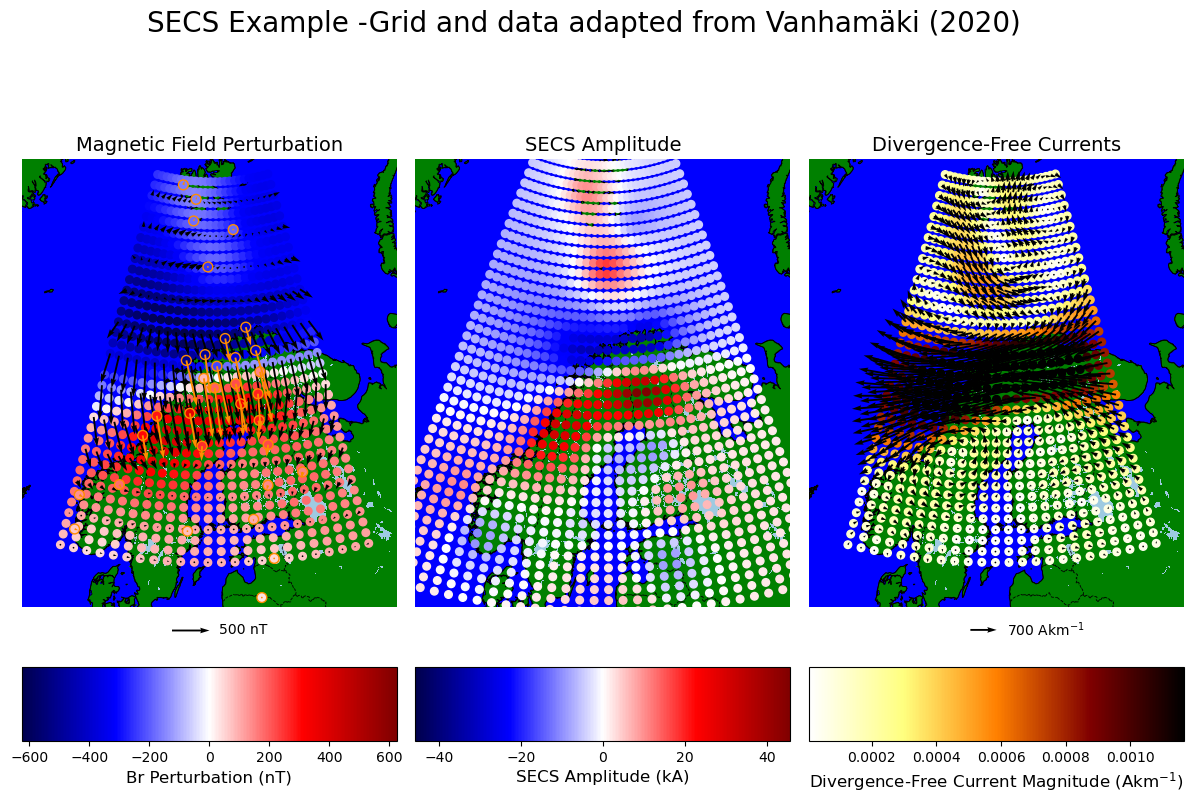

In [11]:
cur_mag = np.sqrt(Cur[0]**2 + Cur[1]**2) * 1e-3

cur_quiver= cur_ax.quiver(eval_xi, eval_eta,
                *plot_grid.projection.vector_cube_projection(Cur[0]*1e3, Cur[1]*1e3,
                                                                eval_lon, eval_lat,
                                                                return_xi_eta=False),
                zorder=100, color='k', scale=1e4, width=0.005)
cur_ax.quiverkey(cur_quiver, 0.5, -0.05, 700, label='700 Akm$^{-1}$', labelpos='E', coordinates='axes')
cur_s= cur_ax.scatter(eval_xi, eval_eta, marker= 'o',
                        c= cur_mag, cmap= 'afmhot_r', zorder=1, s=30,
                        vmin= np.min(cur_mag), vmax= .6*np.max(cur_mag))
cur_cbar= fig.colorbar(cur_s, cax=cur_cax, orientation='horizontal')
cur_cbar.set_label('Divergence-Free Current Magnitude (Akm$^{-1}$)', fontsize=12)
fig